# Kiểm thử Projector đã train: pipeline và bằng chứng

Pipeline: **audio 16 kHz → wav2vec2 B đóng băng → Linear/GELU/Linear → Qwen3-0.6B → text**.
Cascade đối chứng: **audio → B CTC → nhãn lỗi dự đoán → Qwen gốc / LoRA → JSON**.
Hai nhánh giữ riêng trọng số. Notebook này không train, không gọi API ngoài.

**Checkpoint hiện có mới hoàn tất alignment transcript, chưa có P1 học phản hồi lỗi.**
NLL transcript được đo đủ 900 test; sinh transcript và phản hồi dùng pilot cố định cân bằng speaker.
Run All đọc kết quả đã lưu. Hai cell chạy suy luận/đánh giá có cờ mặc định False.

In [1]:
import os, sys, json, subprocess
from pathlib import Path
import pandas as pd
from IPython.display import display, Image, Audio, HTML
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'scripts/run_projector_validation.py').exists())
os.chdir(ROOT)
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from scripts.projector_data import read_json, load
from scripts.report_projector_validation import report
settings = read_json(ROOT/'configs/projector_validation.json')
config = read_json(ROOT/settings['projector_config'])
parts, manifest = load(config)
OUTPUT = ROOT/settings['output_dir']
REPORT = OUTPUT/'report'
PYTHON = ROOT/('.venv/Scripts/python.exe' if os.name=='nt' else '.venv/bin/python')
summary = report(settings)
print('Report:', REPORT/'report.html')
print('Trạng thái:', summary['status'])

{
  "status": "completed_available_checkpoint_validation",
  "report": "D:\\NCC\\MDD\\data\\generated\\projector-validation-v1\\report\\report.html",
  "completed_feedback_cases": 5
}
Report: D:\NCC\MDD\data\generated\projector-validation-v1\report\report.html
Trạng thái: completed_available_checkpoint_validation


## 1. Dữ liệu đã khóa và tình trạng model

Split 2.249 train / 450 validation / 900 test, không trùng speaker; test 6 speaker × 150.
Câu đọc có thể trùng giữa split. Feedback train là nhãn GPT-4o của tác giả; test được tác giả kiểm tra bằng người.
Không lấy nhãn lỗi gold làm đầu vào Projector hoặc cascade thực tế.

,split,speaker,utterances
0,train,ABA,150
1,train,ASI,150
2,train,BWC,150
3,train,EBVS,150
4,train,ERMS,150
5,train,HKK,150
6,train,HQTV,150
7,train,MBMPS,150
8,train,NCC,150
9,train,RRBI,150


,stage,status,optimizer_steps,validation_transcript_loss,trainable_projector,trainable_qwen,trainable_encoder,elapsed_min
0,alignment,completed,282,3.464111,1837056,0,0,19.3401


Feedback stage: not_trained


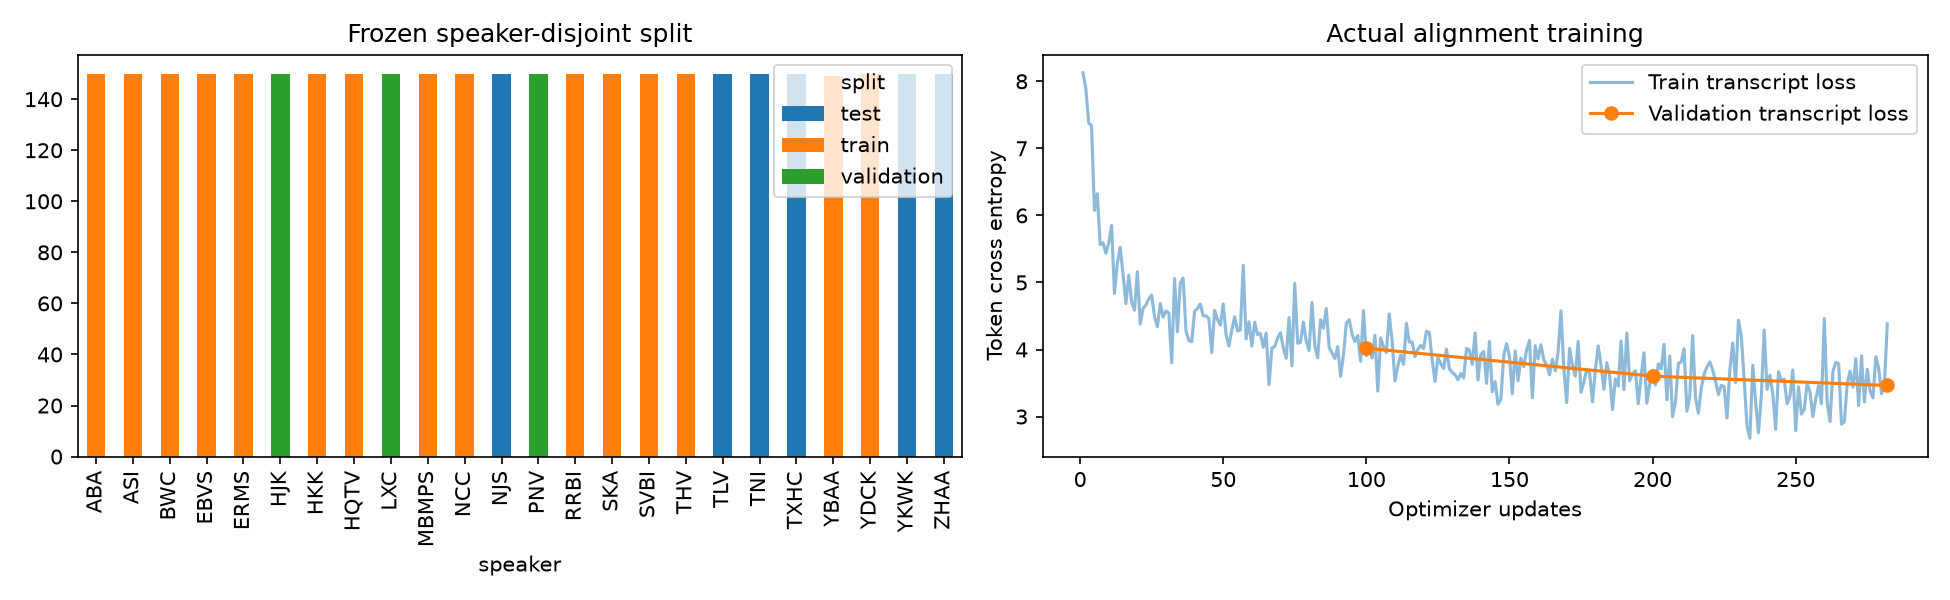

In [2]:
display(pd.read_csv(REPORT/'dataset_counts.csv'))
provenance = summary['projector_alignment']
display(pd.DataFrame([{
    'stage': provenance['stage'], 'status': provenance['status'],
    'optimizer_steps': provenance['optimizer_steps'], 'validation_transcript_loss': provenance['best_validation_loss'],
    'trainable_projector': provenance['parameter_counts']['projector_trainable'],
    'trainable_qwen': provenance['parameter_counts']['llm_trainable'],
    'trainable_encoder': provenance['parameter_counts']['encoder_trainable'],
    'elapsed_min': provenance['elapsed_sec']/60
}]))
print('Feedback stage:', summary['feedback_projector_stage'])
display(Image(filename=str(REPORT/'data_and_training.png')))

## 2. wav2vec2 A/B: đủ 900 test trên cùng split

A là model sau source training; B tiếp tục thích nghi giọng Việt. Đây không phải so sánh wav2vec gốc chưa có CTC head.
F1 tính trên lỗi âm vị theo rubric của project; PER là lỗi nhận dạng chuỗi âm. Không diễn giải F1 thành accuracy.

,case,rows,precision_percent,recall_percent,f1_percent,far_percent,frr_percent,der_percent,per_percent,word_precision_percent,word_recall_percent,word_f1_percent
0,A,900,47.683440,49.087175,48.375127,50.912825,9.099321,33.788878,16.849452,64.691204,60.255665,62.394705
1,B,900,48.771773,49.840256,49.300226,50.159744,8.838715,35.813953,16.705057,65.076395,60.633353,62.776357


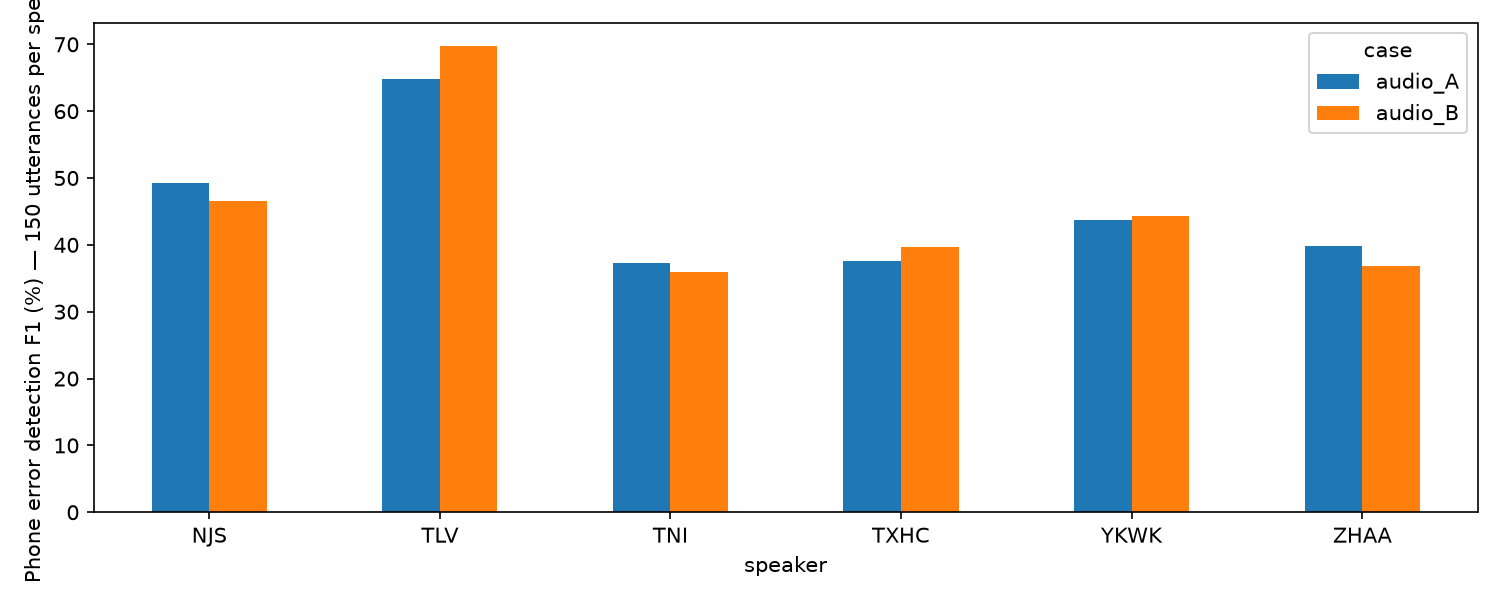

In [3]:
display(pd.DataFrame(summary['audio_full_test']))
display(Image(filename=str(REPORT/'audio_by_speaker.png')))

## 3. Projector: trước/sau alignment và đối chứng tắt audio

Random là projector khởi tạo theo seed cố định, **không phải checkpoint step 0 đã lưu của lượt train**.
Aligned là checkpoint tốt nhất được chọn bằng validation; Muted dùng đúng checkpoint nhưng đặt latent audio bằng 0.
NLL đo teacher forcing đủ 900 test (nhỏ hơn tốt hơn); không phải phần trăm nhận dạng đúng.
WER sinh tự do dùng pilot 5 mẫu/speaker = 30, không đưa câu chuẩn vào prompt transcript. WER có thể >100% khi sinh từ thừa.
Chuẩn hóa case và dấu câu, giữ nguyên từ Unicode để không bỏ qua hallucination bằng ngôn ngữ khác.

,case,rows,target_tokens,target_token_nll,perplexity
0,transcript_nll_random,900,9911,7.225565,1374.115187
1,transcript_nll_aligned,900,9911,3.677308,39.539798
2,transcript_nll_muted,900,9911,6.458484,638.092842


{'delta_nll_after_minus_before': -3.5482575931560856,
 'ci95': [-3.5834792827299635, -3.511515277789582],
 'clusters': 6,
 'resampling_unit': 'speaker'}

{'delta_nll_after_minus_before': -2.781176083086838,
 'ci95': [-2.795881182069661, -2.7650031885212214],
 'clusters': 6,
 'resampling_unit': 'speaker'}

,case,rows,reference_words,wer_percent,exact_sentence_percent,eos_percent,mean_generation_sec
0,transcript_generation_random,30,268,161.567164,0.0,76.666667,2.181444
1,transcript_generation_aligned,30,268,97.388060,0.0,100.000000,0.492812
2,transcript_generation_muted,30,268,727.238806,0.0,0.000000,7.185338


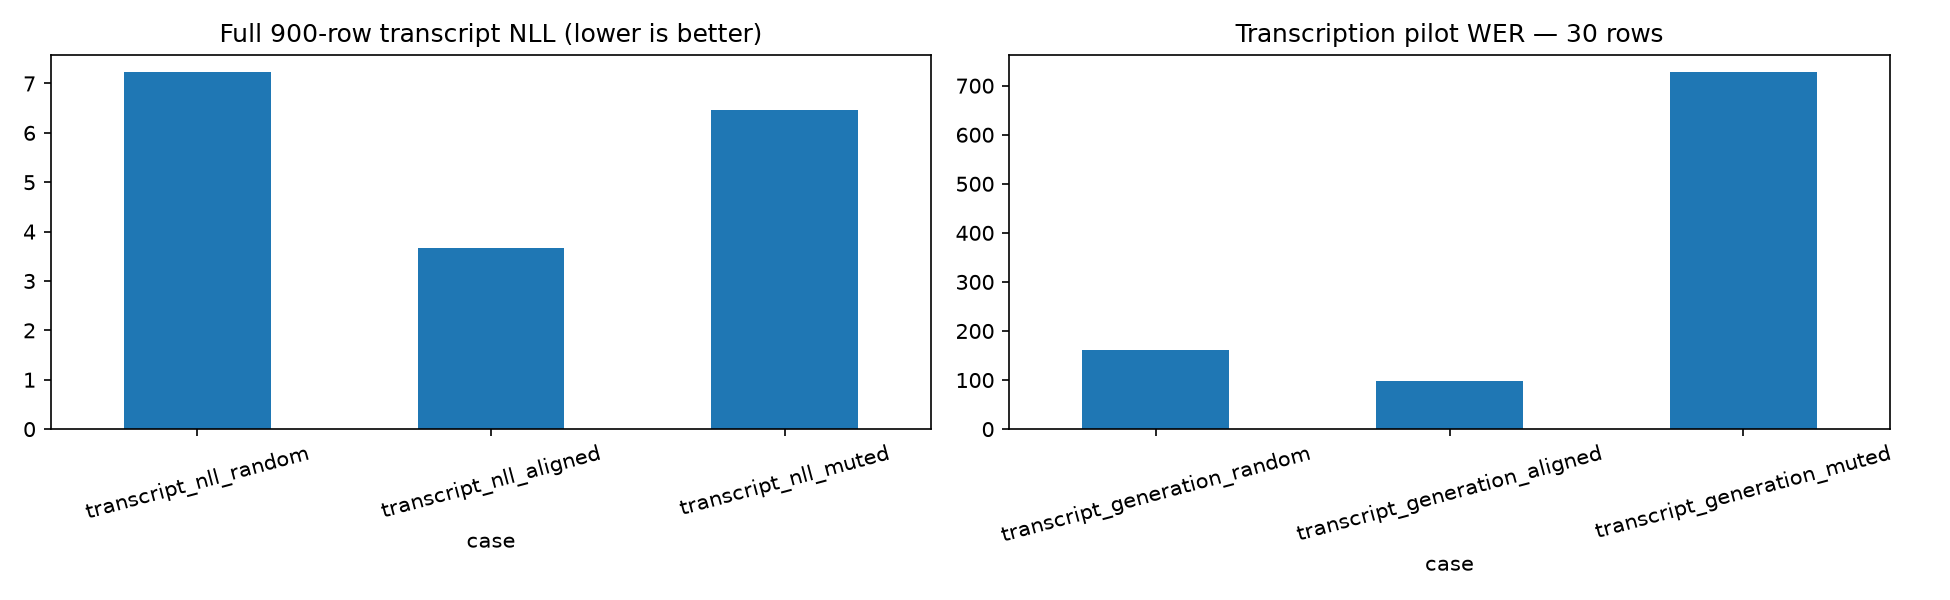

In [4]:
display(pd.DataFrame(summary['transcript_full_nll']))
display(summary.get('alignment_delta', {}))
display(summary.get('audio_ablation_delta', {}))
display(pd.DataFrame(summary['transcript_generation_pilot']))
if (REPORT/'projector_transcription.png').exists():
    display(Image(filename=str(REPORT/'projector_transcription.png')))

## 4. Phản hồi lỗi: cùng pilot cân bằng 12 mẫu

P0 chỉ qua alignment, chưa được train schema/issue/suggestion. B_Q0/B_Q1 dùng lỗi từ B dự đoán.
Projector + cascade_adapter_transfer ghép hai thành phần đã train, chưa học chung audio + feedback nên không gọi là P1.
Oracle_Q1 nhận nhãn âm gold, chỉ là chẩn đoán khả năng Qwen; không đại diện pipeline triển khai.
Cùng greedy decoding, tối đa 512 token; output thiếu EOS, JSON lỗi hoặc schema sai vẫn nằm trong mẫu số.
Word-key F1 và ROUGE-L là độ khớp nhãn từ/lời khuyên, khác F1 âm vị; chưa đánh giá chất lượng sư phạm bằng người.

,case,rows,reference_error_rows,json_valid_percent,grounded_json_percent,feedback_word_precision_percent,feedback_word_recall_percent,feedback_word_f1_percent,suggestion_bleu2,bleu_signature,suggestion_rougeL_on_reference_error_rows,correct_empty_feedback_percent,target_token_nll,target_perplexity,nll_rows,nll_target_tokens,latency_median_sec,latency_p95_sec,generation_tokens_per_sec
0,feedback_projector_P0,12,12,16.666667,0.0,0.000000,0.000000,0.000000,2.742194e-20,nrefs:1|case:mixed|eff:yes|tok:13a|smooth:exp|...,1.799887,None,2.041789,7.704380,12,2994,3.494503,28.971468,18.281581
1,feedback_cascade_B_Q0,12,12,0.000000,0.0,0.000000,0.000000,0.000000,0.000000e+00,nrefs:1|case:mixed|eff:yes|tok:13a|smooth:exp|...,0.000000,None,2.055609,7.811595,12,2812,13.596324,25.100587,17.623068
2,feedback_cascade_B_Q1,12,12,100.000000,100.0,65.000000,60.465116,62.650602,3.750981e+01,nrefs:1|case:mixed|eff:yes|tok:13a|smooth:exp|...,22.657361,None,0.864316,2.373381,12,2812,14.320745,25.304427,14.274783
3,feedback_oracle_Q1,12,12,83.333333,75.0,91.891892,79.069767,85.000000,4.742482e+01,nrefs:1|case:mixed|eff:yes|tok:13a|smooth:exp|...,36.624660,None,0.596215,1.815236,12,2812,18.089009,28.664589,14.714875
4,feedback_projector_cascade_adapter_transfer,12,12,25.000000,25.0,0.000000,0.000000,0.000000,0.000000e+00,nrefs:1|case:mixed|eff:yes|tok:13a|smooth:exp|...,0.000000,None,1.204372,3.334663,12,2994,2.146957,18.407991,15.626981


{'metric': 'suggestion_rougeL_on_reference_error_rows',
 'unit': 'percentage_points_after_minus_before',
 'delta': 22.657360803176278,
 'ci95': [14.427070698336818, 30.73586899390787],
 'resampling_unit': 'speaker',
 'clusters': 6,
 'repetitions': 2000,
 'seed': 42,
 'scope': 'Paired held-out sample uncertainty for this training seed; not variation across training seeds'}

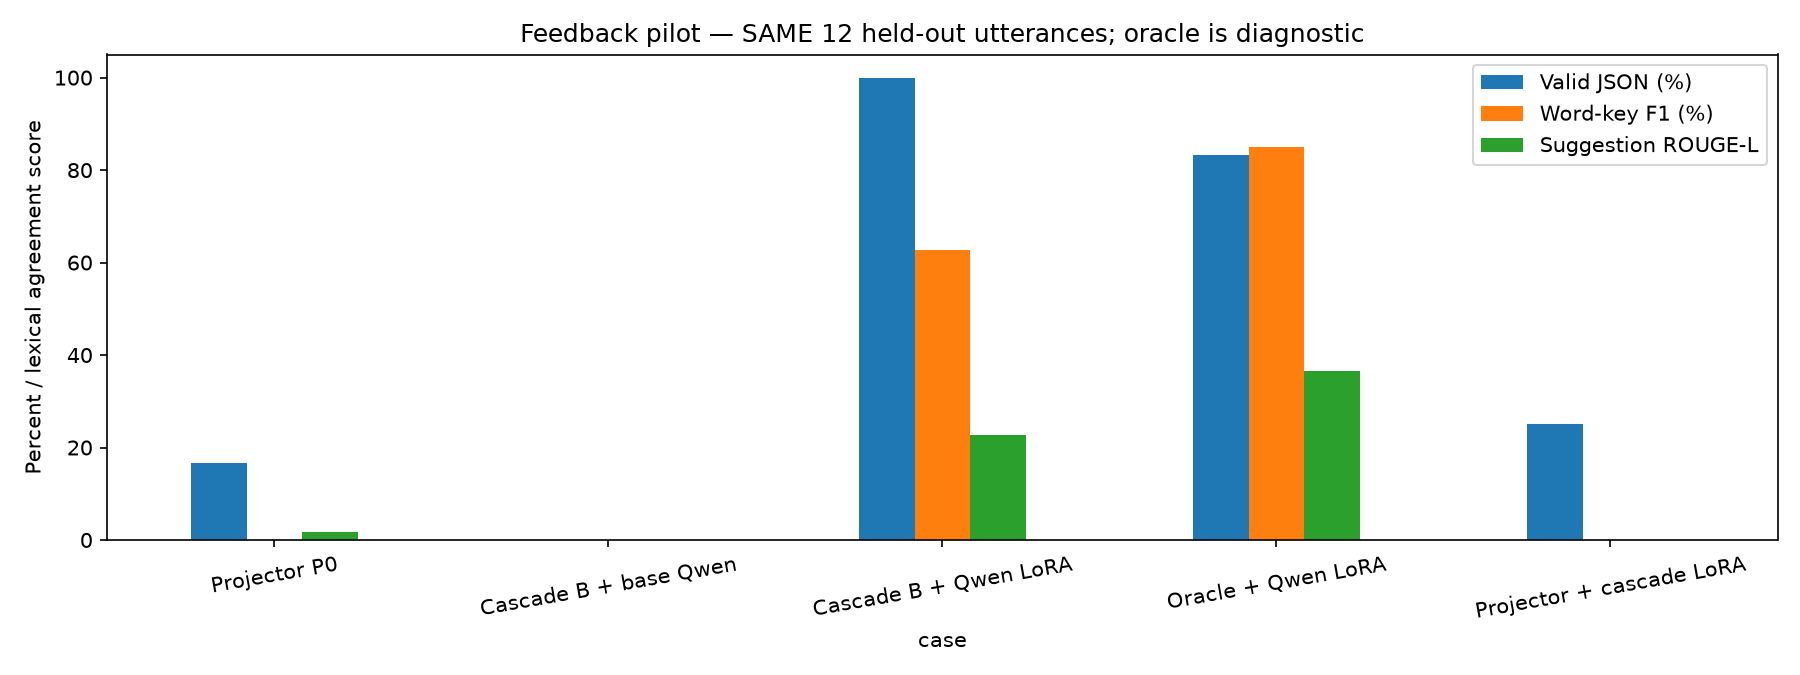

,case,speaker,rows,phone_f1_percent,reference_words,wer_percent,exact_sentence_percent,eos_percent,mean_generation_sec,reference_error_rows,...,bleu_signature,suggestion_rougeL_on_reference_error_rows,correct_empty_feedback_percent,target_token_nll,target_perplexity,nll_rows,nll_target_tokens,latency_median_sec,latency_p95_sec,generation_tokens_per_sec
0,audio_A,NJS,150,49.309091,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,audio_A,TLV,150,64.804036,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,audio_A,TNI,150,37.324525,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,audio_A,TXHC,150,37.545126,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,audio_A,YKWK,150,43.650794,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,audio_A,ZHAA,150,39.815668,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,audio_B,NJS,150,46.522064,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,audio_B,TLV,150,69.772815,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,audio_B,TNI,150,35.909823,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,audio_B,TXHC,150,39.740821,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
display(pd.DataFrame(summary['feedback_generation_pilot']))
display(summary.get('cascade_qwen_pilot_delta', {}))
if (REPORT/'feedback_pilot.png').exists():
    display(Image(filename=str(REPORT/'feedback_pilot.png')))
if (REPORT/'per_speaker.csv').exists():
    display(pd.read_csv(REPORT/'per_speaker.csv'))

## 5. Audio thật, raw output và lỗi quan sát được

Kiểm tra một bản thu cố định/speaker: mã hóa từ WAV phải trùng chính xác cache đã khóa trước khi đưa vào Projector.
Ví dụ dưới đây theo thứ tự test đã khóa, không chọn theo model thắng/thua. Có thể nghe audio và xem trực tiếp output.

In [6]:
examples = read_json(REPORT/'examples.json')
display(summary.get('raw_audio_parity', {'status':'pending'}))
feedback_examples = [r for r in examples if r['case'].startswith('feedback_')]
ids = list(dict.fromkeys(r['utterance_id'] for r in feedback_examples))
if ids:
    uid = ids[0]
    source = next(r for r in parts['test'] if r['utterance_id']==uid)
    print(uid, source['reference_text'])
    display(Audio(filename=str(ROOT/source['audio_path'])))
    print('Published reference:')
    display(source['feedback'])
    for row in feedback_examples:
        if row['utterance_id']==uid:
            print(row['case'], 'JSON:', row['valid_json'], 'EOS:', row['finished_with_eos'])
            print(row.get('validation_error') or '')
            print(row['raw_text'])

{'rows': 6, 'all_exact_match': True}

NJS/arctic_a0054 There was nothing on the rock


Published reference:


{'there': [{'issue': '"DH" was replaced with "D", indicating a substitution error',
   'suggestion': 'Strengthen the articulation of /DH/ by comparing it with /D/ in words like "THIS" (/DH IH S/) vs. "DIS" (/D IH S/)'}],
 'was': [{'issue': '"Z" was replaced with "S", indicating a consonant substitution',
   'suggestion': 'Practice voicing with /Z/ versus /S/ using words like "BUZZ" (/B AH Z/) vs. "BUS" (/B AH S/)'}],
 'nothing': [{'issue': '"NG" was replaced with "N", indicating a substitution error',
   'suggestion': 'Practice the velar nasal /NG/ using minimal pairs like "SING" (/S IH NG/) vs. "SIN" (/S IH N/)'}]}

feedback_projector_P0 JSON: False EOS: True
Expecting value: line 1 column 1 (char 0)
```json
{
  "There was nothing on the rock": [
    {
      "issue": "Learner audio: 'There was nothing on the rock'",
      "suggestion": "Reference: 'There was nothing on the rock'"
    }
  ]
}
```
feedback_cascade_B_Q0 JSON: False EOS: True
Expecting value: line 1 column 1 (char 0)
```json
{
  "affected_word": [
    {
      "issue": "The word 'nothing' has a silent 'n' and a phonetic annotation of 'TH' which is incorrect.",
      "suggestion": "The word 'nothing' should be pronounced as 'nōt-hōn' with the silent 'n' and the 'th' sound."
    },
    {
      "issue": "The word 'rock' has a phonetic annotation of 'K' which is incorrect.",
      "suggestion": "The word 'rock' should be pronounced as 'rōck' with the 'k' sound."
    }
  ]
}
```
feedback_cascade_B_Q1 JSON: True EOS: True

{"there":[{"issue":"\"DH\" was replaced with \"D\", indicating a substitution error","suggestion":"Practice the distinct

## 6. Giới hạn và cách diễn giải

Alignment cải thiện khả năng dùng âm thanh nếu NLL giảm và đối chứng muted kém hơn.
Điều này chưa chứng minh model sửa phát âm chính xác: cần stage feedback và benchmark đủ 900 output trước/sau trên cùng protocol.
Pilot là phép kiểm tra ban đầu để phát hiện lỗi pipeline; chưa dùng để chọn checkpoint hoặc chỉnh tham số.

In [7]:
for item in summary['limitations']: print('•', item)
print('Execution:', summary.get('execution', 'Chưa hoàn tất'))
print('HTML:', REPORT/'report.html')
print('Raw output:', OUTPUT)

• Projector has transcript alignment only; no P1 feedback-stage weights exist.
• Random baseline uses a reproducible new initialization, not an exact saved step-0 checkpoint.
• Transcript NLL is teacher forced and is not a transcription accuracy score.
• Generation metrics are balanced pilots, not a full 900-row generation benchmark.
• Word-key F1 and lexical ROUGE measure agreement with published feedback, not phone F1 or pedagogical correctness.
• Oracle Qwen uses gold phone labels and is diagnostic only, not a deployable audio pipeline.
• Speaker holdout allows shared read prompts; one training seed; 6 held-out speakers.
• Training feedback is authors' GPT-4o supervision; test feedback is authors' human-checked reference.
• All feedback pilot samples have reference errors; this pilot does not measure false alarms on fully correct speech.
Execution: {'status': 'completed', 'peak_allocated_bytes': 1379619328, 'full_transcript_nll_rows': 900, 'transcript_generation_rows': 30, 'feedback

## 7. Tự chạy lại pipeline kiểm thử

Chỉ đánh giá các checkpoint hiện có; không có lệnh train. Resume chỉ chấp nhận cùng hash dữ liệu, trọng số và code.
Để đo generation đủ 900 mẫu: tạo config mới, output_dir mới, đổi cả hai per_speaker thành 150 trước khi chạy.
Không thay đổi config đã dùng cho lượt hiện tại. Lượt 900 generation sẽ lâu hơn pilot.

In [ ]:
RUN_EVALUATION = False
if RUN_EVALUATION:
    subprocess.run([str(PYTHON), '-X', 'utf8', '-u', 'scripts/run_projector_validation.py', '--phase', 'all'], cwd=ROOT, check=True)
else:
    print(str(PYTHON), '-X utf8 -u scripts/run_projector_validation.py --phase all')
    print('Mặc định chỉ in lệnh. Log: '+str(OUTPUT/'checkpoint_benchmark.log'))

## 8. Thử một WAV riêng qua toàn bộ pipeline

Mặc định dùng một audio test để minh họa transcription. Đổi AUDIO_FILE sang file của bạn.
Với `--task feedback`, cần thêm `--reference` và câu chuẩn; checkpoint alignment sẽ ghi rõ chưa học feedback.

In [ ]:
RUN_AUDIO_INFERENCE = False
USE_CASCADE_ADAPTER = False  # True: thử ghép Projector + LoRA cascade; không phải P1.
AUDIO_FILE = ROOT/parts['test'][0]['audio_path']
if RUN_AUDIO_INFERENCE:
    command = [str(PYTHON), '-X', 'utf8']
    if USE_CASCADE_ADAPTER:
        command += ['scripts/projector_composed_inference.py', '--audio', str(AUDIO_FILE),
                    '--reference', parts['test'][0]['reference_text'], '--output', str(OUTPUT/'my_audio_result.json')]
    else:
        command += ['scripts/projector_inference.py', '--audio', str(AUDIO_FILE), '--task', 'alignment',
                    '--max-new-tokens', '128', '--output', str(OUTPUT/'my_audio_result.json')]
    subprocess.run(command, cwd=ROOT, check=True)
    display(read_json(OUTPUT/'my_audio_result.json'))
else:
    print('Đổi RUN_AUDIO_INFERENCE=True khi muốn tự chạy thử WAV.')